In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

print("Machine Learning Workflow Environment Ready!")

Machine Learning Workflow Environment Ready!


In [2]:
np.random.seed(42)

n = 500

df = pd.DataFrame({
    "Area": np.random.randint(500, 4000, n),
    "Bedrooms": np.random.randint(1, 6, n),
    "Bathrooms": np.random.randint(1, 5, n),
    "Age": np.random.randint(0, 30, n),
    "Location": np.random.choice(
        ["Hyderabad", "Chennai", "Bangalore", "Mumbai"],
        n
    )
})

location_price = df["Location"].map({
    "Hyderabad": 3000,
    "Chennai": 2800,
    "Bangalore": 3500,
    "Mumbai": 4500
})

df["Price"] = (
    df["Area"] * location_price
    + df["Bedrooms"] * 200000
    + df["Bathrooms"] * 100000
    - df["Age"] * 15000
    + np.random.normal(0, 200000, n)
)

df["Price"] = df["Price"].clip(lower=500000)

print("Dataset Collected Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Collected Successfully!
Dataset Shape: (500, 6)


,Area,Bedrooms,Bathrooms,Age,Location,Price
0,3674,4,4,16,Bangalore,1.394155e+07
1,1360,2,3,13,Mumbai,6.414317e+06
2,1794,3,2,8,Hyderabad,5.937246e+06
3,1630,4,2,7,Mumbai,8.612806e+06
4,1595,5,4,1,Chennai,5.812864e+06


In [3]:
# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (500, 6)

Column Names:
['Area', 'Bedrooms', 'Bathrooms', 'Age', 'Location', 'Price']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Area       500 non-null    int32  
 1   Bedrooms   500 non-null    int32  
 2   Bathrooms  500 non-null    int32  
 3   Age        500 non-null    int32  
 4   Location   500 non-null    str    
 5   Price      500 non-null    float64
dtypes: float64(1), int32(4), str(1)
memory usage: 19.5 KB

Statistical Summary:


,Area,Bedrooms,Bathrooms,Age,Location,Price
count,500.00000,500.000000,500.00000,500.000000,500,5.000000e+02
unique,NaN,NaN,NaN,NaN,4,NaN
top,NaN,NaN,NaN,NaN,Mumbai,NaN
freq,NaN,NaN,NaN,NaN,130,NaN
mean,2319.38400,3.052000,2.50000,14.546000,NaN,8.727095e+06
std,1003.67328,1.462043,1.10292,8.729507,NaN,4.005335e+06
min,501.00000,1.000000,1.00000,0.000000,NaN,1.595950e+06
25%,1478.75000,2.000000,2.00000,7.000000,NaN,5.646800e+06
50%,2297.50000,3.000000,3.00000,14.000000,NaN,8.367807e+06
75%,3208.00000,4.000000,3.00000,23.000000,NaN,1.147057e+07



Missing Values:


Area         0
Bedrooms     0
Bathrooms    0
Age          0
Location     0
Price        0
dtype: int64


Duplicate Records: 0


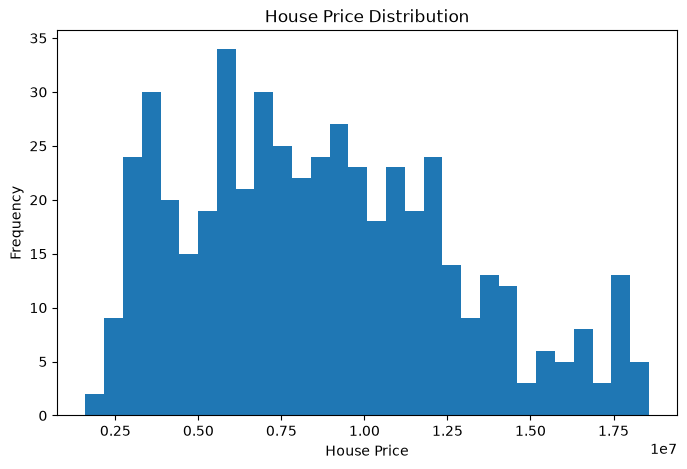

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price"], bins=30)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

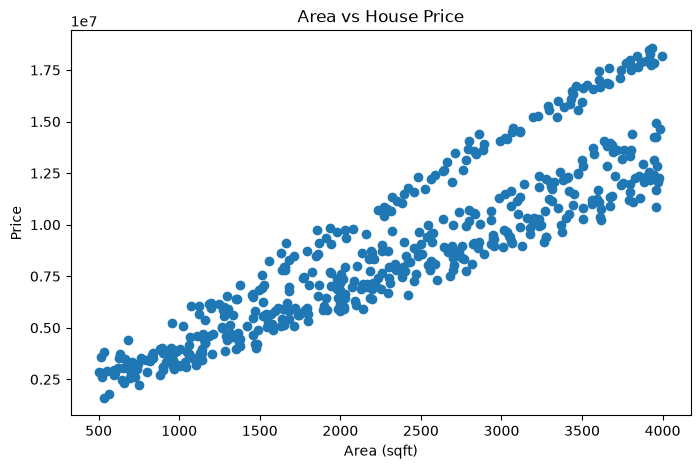

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Area"], df["Price"])

plt.title("Area vs House Price")
plt.xlabel("Area (sqft)")
plt.ylabel("Price")

plt.show()

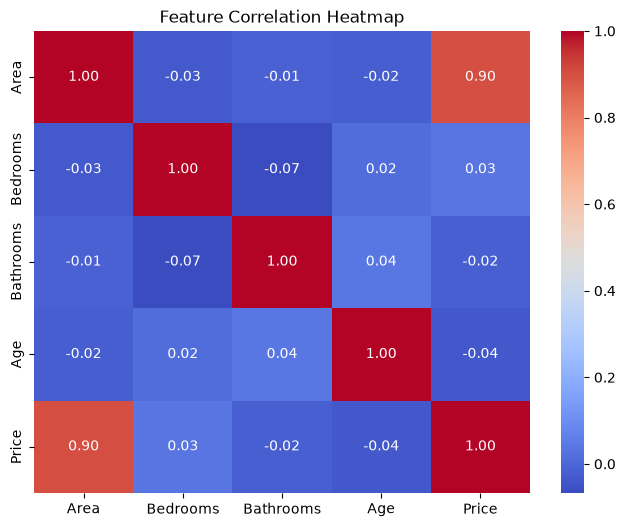

In [6]:
numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [7]:
# Create a copy of the dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Handle missing numerical values
numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns

df_clean[numerical_columns] = (
    df_clean[numerical_columns]
    .fillna(df_clean[numerical_columns].median())
)

# Handle missing categorical values
categorical_columns = df_clean.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

print("Data Preprocessing Completed!")
print("Cleaned Dataset Shape:", df_clean.shape)

display(df_clean.head())

Data Preprocessing Completed!
Cleaned Dataset Shape: (500, 6)


,Area,Bedrooms,Bathrooms,Age,Location,Price
0,3674,4,4,16,Bangalore,1.394155e+07
1,1360,2,3,13,Mumbai,6.414317e+06
2,1794,3,2,8,Hyderabad,5.937246e+06
3,1630,4,2,7,Mumbai,8.612806e+06
4,1595,5,4,1,Chennai,5.812864e+06


In [8]:
# Total number of rooms
df_clean["Total_Rooms"] = (
    df_clean["Bedrooms"] + df_clean["Bathrooms"]
)

# Property age category
df_clean["Property_Age_Category"] = pd.cut(
    df_clean["Age"],
    bins=[-1, 5, 15, 30],
    labels=["New", "Moderate", "Old"]
)

# Area per bedroom
df_clean["Area_Per_Bedroom"] = (
    df_clean["Area"] / df_clean["Bedrooms"]
)

print("Feature Engineering Completed!")

display(df_clean.head())

Feature Engineering Completed!


,Area,Bedrooms,Bathrooms,Age,Location,Price,Total_Rooms,Property_Age_Category,Area_Per_Bedroom
0,3674,4,4,16,Bangalore,1.394155e+07,8,Old,918.5
1,1360,2,3,13,Mumbai,6.414317e+06,5,Moderate,680.0
2,1794,3,2,8,Hyderabad,5.937246e+06,5,Moderate,598.0
3,1630,4,2,7,Mumbai,8.612806e+06,6,Moderate,407.5
4,1595,5,4,1,Chennai,5.812864e+06,9,New,319.0


In [9]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=["Price"])
y = df_clean["Price"]

# Encode categorical features
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train/Test Split Completed!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Train/Test Split Completed!
X_train: (400, 11)
X_test: (100, 11)
y_train: (400,)
y_test: (100,)


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Define candidate models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

print("Available Models for Selection:")

for name in models:
    print("-", name)

Available Models for Selection:
- Linear Regression
- Random Forest


In [11]:
# Train both candidate models
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    print(name, "trained successfully!")

Linear Regression trained successfully!
Random Forest trained successfully!


In [12]:
# Generate predictions
predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test)

    print(f"{name} Predictions:")
    print(predictions[name][:5])
    print("-" * 40)

Linear Regression Predictions:
[10665462.48920232 10012917.1475097   8476963.00777611 10956767.00004138
  4327878.28920022]
----------------------------------------
Random Forest Predictions:
[10260256.719486    9701129.57637933  8210358.22157745 10025263.55961509
  4754180.77872117]
----------------------------------------


In [13]:
new_house = X_test.iloc[[0]]

new_prediction = trained_models["Random Forest"].predict(
    new_house
)

print("Predicted House Price:", new_prediction[0])

Predicted House Price: 10260256.719486


In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

evaluation_results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(evaluation_results)

display(results_df)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,525216.607719,700815.526331,0.966102
1,Random Forest,324123.966005,396170.098030,0.989167


In [15]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter combinations
param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

# Create Random Forest model
rf = RandomForestRegressor(random_state=42)

# Configure Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Train using training data
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-grid_search.best_score_)

Best Hyperparameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 150}

Best Cross-Validation MAE:
379121.8858014172


In [16]:
best_model = grid_search.best_estimator_

# Predictions from tuned model
tuned_predictions = best_model.predict(X_test)

# Final evaluation
final_mae = mean_absolute_error(
    y_test, tuned_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

final_r2 = r2_score(
    y_test, tuned_predictions
)

print("Final Tuned Random Forest Results")
print("----------------------------------")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Tuned Random Forest Results
----------------------------------
MAE: 322858.4099003173
RMSE: 393286.4412528527
R2 Score: 0.9893245995858393


In [17]:
import joblib

# Save trained model
joblib.dump(
    best_model,
    "house_price_prediction_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [18]:
# Load saved model
loaded_model = joblib.load(
    "house_price_prediction_model.pkl"
)

# Predict using loaded model
prediction = loaded_model.predict(X_test.iloc[[0]])

print("Loaded Model Prediction:", prediction[0])

Loaded Model Prediction: 10330759.998993564
